# Tour Completo pelas 6 Etapas Oficiais (`experimental-ml`)

Este notebook acompanha o [Tutorial das 6 Etapas](../docs/guia/02_tutorial_6_etapas.md) mostrando passo a passo o que cada etapa do protocolo científico produz e valida, do diagnóstico da base até o relatório e gráfico **SVG**.

In [1]:
# Instalação automática apenas quando executado no Google Colab
import subprocess, sys
if "google.colab" in sys.modules:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "git+https://github.com/aleerangel/experimental-ml-framework.git",
    ])

In [2]:
# Helper de exibição rica (funciona em Jupyter/Colab e em Python puro)
def exibir_markdown(texto: str) -> None:
    try:
        from IPython.display import Markdown, display
        display(Markdown(texto))
    except ImportError:
        print(texto)

def exibir_svg(svg_bytes: bytes | str) -> None:
    svg_str = svg_bytes.decode("utf-8") if isinstance(svg_bytes, bytes) else svg_bytes
    try:
        from IPython.display import SVG, display
        display(SVG(svg_str))
    except ImportError:
        print(f"[Figura SVG gerada: {len(svg_str)} caracteres]")

## Etapa 1 — Entrada, Triagem e Diagnóstico Estrutural

In [3]:
from pathlib import Path
import tempfile
import numpy as np

from experimental_ml.core.enums import MetricDirection, TaskType
from experimental_ml.data import (
    DatasetSchemaSpec,
    create_preparation_plan,
    load_dataset,
    profile_dataset,
    sanitize_dataset,
)

rng = np.random.default_rng(42)
y = np.array([0] * 30 + [1] * 30)
dados = {
    "biomarcador": rng.normal(loc=y * 1.4, scale=0.8).tolist(),
    "ruido": rng.normal(loc=0.0, scale=1.0, size=60).tolist(),
    "alvo": y.tolist(),
}
schema = DatasetSchemaSpec(target_col="alvo", task_type=TaskType.BINARY_CLASSIFICATION)
bundle = load_dataset(dados, schema)
profile = profile_dataset(bundle)
plan = create_preparation_plan(profile, rules=[])
view = sanitize_dataset(bundle, profile, plan)
print(f"Etapa 1 concluída: {len(view.observation_ids)} amostras válidas | Hash: {view.dataset_hash[:16]}...")

Etapa 1 concluída: 60 amostras válidas | Hash: e705558051ef7501...


## Etapa 2 — Exploração de Relações e Cenários de Features

In [4]:
from experimental_ml.features import FeatureScenario, ScenarioMode, explore_features, validate_scenarios

exp_report = explore_features(view)
print(f"Escopo exploratório obrigatório: {exp_report.scope}")

cenarios = validate_scenarios([
    FeatureScenario(
        scenario_id="todas",
        name="Todas as Features",
        description="Biomarcador + ruído",
        scientific_justification="Cenário completo",
        mode=ScenarioMode.FIXED,
        selected_features=("biomarcador", "ruido"),
    ),
    FeatureScenario(
        scenario_id="somente_bio",
        name="Somente Biomarcador",
        description="Apenas variável informativa",
        scientific_justification="Cenário parcimonioso",
        mode=ScenarioMode.FIXED,
        selected_features=("biomarcador",),
    ),
], view)
print(f"Etapa 2 concluída: {len(cenarios.scenarios)} cenários validados.")

Escopo exploratório obrigatório: EXPLORATORY_FULL_DATA
Etapa 2 concluída: 2 cenários validados.


## Etapa 3 — Registro de Modelos e Capacidades

In [5]:
from experimental_ml.models import DummyBaselineModel, ModelCapabilities, ModelFamily, ModelSpec, validate_model_spec

class ClassificadorLinearSimples:
    def fit(self, X: np.ndarray, y: np.ndarray) -> "ClassificadorLinearSimples":
        X_aug = np.column_stack([X, np.ones(len(X))])
        coef, *_ = np.linalg.lstsq(X_aug, y.astype(float), rcond=None)
        self.w_ = coef[:-1]
        self.b_ = float(coef[-1])
        return self

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        z = np.clip(X @ self.w_ + self.b_, -20.0, 20.0)
        p1 = 1.0 / (1.0 + np.exp(-z))
        return np.column_stack([1.0 - p1, p1])

    def predict(self, X: np.ndarray) -> np.ndarray:
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

modelos = [
    validate_model_spec(ModelSpec(
        model_id="dummy_freq",
        display_name="Dummy Majoritário",
        family=ModelFamily.BASELINE,
        estimator_factory=lambda seed=None: DummyBaselineModel(strategy="most_frequent"),
        capabilities=ModelCapabilities(supports_predict_proba=True),
        description="Baseline majoritário",
        scientific_justification="Referência mínima",
    )),
    validate_model_spec(ModelSpec(
        model_id="linear_clf",
        display_name="Classificador Linear",
        family=ModelFamily.CLASSICAL_ML,
        estimator_factory=lambda seed=None: ClassificadorLinearSimples(),
        capabilities=ModelCapabilities(supports_predict_proba=True),
        description="Classificador linear simples",
        scientific_justification="Modelo paramétrico",
    )),
]
print(f"Etapa 3 concluída: {len(modelos)} modelos validados.")

Etapa 3 concluída: 2 modelos validados.


## Etapa 4 — Particionamento (4A) e Execução Matricial (4B)

In [6]:
from experimental_ml.orchestration import load_cell_artifacts, run_experiment_matrix
from experimental_ml.validation import EvaluationRegime, PartitionConfig, PartitionStrategy, build_partition_plan

exp_dir = Path(tempfile.mkdtemp(prefix="expml_6etapas_"))
part_plan = build_partition_plan(
    view,
    PartitionConfig(strategy=PartitionStrategy.STRATIFIED_KFOLD, regime=EvaluationRegime.CV_ONLY, n_splits=5, master_seed=42),
)
run_state = run_experiment_matrix(
    model_specs=modelos,
    scenarios=cenarios.scenarios,
    partition_plan=part_plan,
    sanitized_view=view,
    run_dir=exp_dir / "runs",
    metrics=("accuracy", "f1", "roc_auc"),
    master_seed=42,
    overwrite=True,
)
print(f"Etapa 4 concluída: {run_state.completed_cells}/{run_state.total_cells} células executadas.")

Etapa 4 concluída: 20/20 células executadas.


## Etapa 5 — Consolidação e Comparação Estatística

In [7]:
from experimental_ml.statistics import (
    ComparisonScope,
    ComparisonSpec,
    consolidate_descriptive,
    evaluate_method_suitability,
    run_statistical_comparisons,
    save_statistics_artifacts,
    synthesize_conclusions,
)

cells = [load_cell_artifacts(cid, exp_dir / "runs")[0] for cid in run_state.cell_statuses]
cons = consolidate_descriptive(
    cells, total_folds_per_config=len(part_plan.folds),
    experiment_id=run_state.experiment_id, partition_plan_id=part_plan.plan_id,
)
suit = evaluate_method_suitability(part_plan, cons)
comp = run_statistical_comparisons(
    cons, part_plan,
    ComparisonSpec(
        metrics_of_interest=("accuracy", "f1", "roc_auc"),
        metric_directions={"accuracy": MetricDirection.MAXIMIZE, "f1": MetricDirection.MAXIMIZE, "roc_auc": MetricDirection.MAXIMIZE},
        comparison_scope=ComparisonScope.ALL_PAIRWISE, alpha=0.05,
    ),
    suit,
)
conc = synthesize_conclusions(cons, suit, comp, primary_metric="accuracy", primary_direction=MetricDirection.MAXIMIZE)
save_statistics_artifacts(exp_dir / "statistics", cons, suit, comp, conc, force=True)
print(f"Etapa 5 concluída — Líder observado: {conc.observed_leader}")

Etapa 5 concluída — Líder observado: ('linear_clf', 'todas')


## Etapa 6 — Relatórios Científicos e Gráfico SVG

### Desempenho Preditivo

### Predictive Performance

| Model | Scenario | Metric | Status | Mean | SD | Median | IQR | Coverage |
| :--- | :--- | :--- | :---: | ---: | ---: | ---: | ---: | ---: |
| dummy_freq | somente_bio | accuracy | VALID | 0.5000 | 0.0000 | 0.5000 | 0.0000 | 100.00% |
| dummy_freq | somente_bio | f1 | VALID | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 100.00% |
| dummy_freq | somente_bio | roc_auc | VALID | 0.5000 | 0.0000 | 0.5000 | 0.0000 | 100.00% |
| dummy_freq | todas | accuracy | VALID | 0.5000 | 0.0000 | 0.5000 | 0.0000 | 100.00% |
| dummy_freq | todas | f1 | VALID | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 100.00% |
| dummy_freq | todas | roc_auc | VALID | 0.5000 | 0.0000 | 0.5000 | 0.0000 | 100.00% |
| linear_clf | somente_bio | accuracy | VALID | 0.6167 | 0.0745 | 0.6667 | 0.0833 | 100.00% |
| linear_clf | somente_bio | f1 | VALID | 0.7245 | 0.0376 | 0.7500 | 0.0441 | 100.00% |
| linear_clf | somente_bio | roc_auc | VALID | 0.9611 | 0.0248 | 0.9444 | 0.0278 | 100.00% |
| linear_clf | todas | accuracy | VALID | 0.6167 | 0.0745 | 0.6667 | 0.0833 | 100.00% |
| linear_clf | todas | f1 | VALID | 0.7245 | 0.0376 | 0.7500 | 0.0441 | 100.00% |
| linear_clf | todas | roc_auc | VALID | 0.9611 | 0.0248 | 0.9444 | 0.0278 | 100.00% |


### Comparações Estatísticas

### Statistical Comparisons

| Config A | Config B | Metric | Diff | t (NB) | p_adj (NB) | p_adj (WX) | Cohen d_z | Practical Relevance |
| :--- | :--- | :--- | ---: | ---: | ---: | ---: | ---: | :--- |
| dummy_freq/somente_bio | dummy_freq/todas | accuracy | 0.0000 | 0.0000 | 1.0000 | 1.0000 | 0.0000 | NOT_CONFIGURED |
| dummy_freq/somente_bio | linear_clf/somente_bio | accuracy | -0.1167 | -2.3333 | 0.4798 | 0.7500 | -1.5652 | NOT_CONFIGURED |
| dummy_freq/somente_bio | linear_clf/todas | accuracy | -0.1167 | -2.3333 | 0.4798 | 0.7500 | -1.5652 | NOT_CONFIGURED |
| dummy_freq/todas | linear_clf/somente_bio | accuracy | -0.1167 | -2.3333 | 0.4798 | 0.7500 | -1.5652 | NOT_CONFIGURED |
| dummy_freq/todas | linear_clf/todas | accuracy | -0.1167 | -2.3333 | 0.4798 | 0.7500 | -1.5652 | NOT_CONFIGURED |
| linear_clf/somente_bio | linear_clf/todas | accuracy | 0.0000 | 0.0000 | 1.0000 | 1.0000 | 0.0000 | NOT_CONFIGURED |
| dummy_freq/somente_bio | dummy_freq/todas | f1 | 0.0000 | 0.0000 | 1.0000 | 1.0000 | 0.0000 | NOT_CONFIGURED |
| dummy_freq/somente_bio | linear_clf/somente_bio | f1 | -0.7245 | -28.7574 | 0.0001 | 0.3750 | -19.2910 | NOT_CONFIGURED |
| dummy_freq/somente_bio | linear_clf/todas | f1 | -0.7245 | -28.7574 | 0.0001 | 0.3750 | -19.2910 | NOT_CONFIGURED |
| dummy_freq/todas | linear_clf/somente_bio | f1 | -0.7245 | -28.7574 | 0.0001 | 0.3750 | -19.2910 | NOT_CONFIGURED |
| dummy_freq/todas | linear_clf/todas | f1 | -0.7245 | -28.7574 | 0.0001 | 0.3750 | -19.2910 | NOT_CONFIGURED |
| linear_clf/somente_bio | linear_clf/todas | f1 | 0.0000 | 0.0000 | 1.0000 | 1.0000 | 0.0000 | NOT_CONFIGURED |
| dummy_freq/somente_bio | dummy_freq/todas | roc_auc | 0.0000 | 0.0000 | 1.0000 | 1.0000 | 0.0000 | NOT_CONFIGURED |
| dummy_freq/somente_bio | linear_clf/somente_bio | roc_auc | -0.4611 | -27.6667 | 0.0001 | 0.3750 | -18.5594 | NOT_CONFIGURED |
| dummy_freq/somente_bio | linear_clf/todas | roc_auc | -0.4611 | -27.6667 | 0.0001 | 0.3750 | -18.5594 | NOT_CONFIGURED |
| dummy_freq/todas | linear_clf/somente_bio | roc_auc | -0.4611 | -27.6667 | 0.0001 | 0.3750 | -18.5594 | NOT_CONFIGURED |
| dummy_freq/todas | linear_clf/todas | roc_auc | -0.4611 | -27.6667 | 0.0001 | 0.3750 | -18.5594 | NOT_CONFIGURED |
| linear_clf/somente_bio | linear_clf/todas | roc_auc | 0.0000 | 0.0000 | 1.0000 | 1.0000 | 0.0000 | NOT_CONFIGURED |


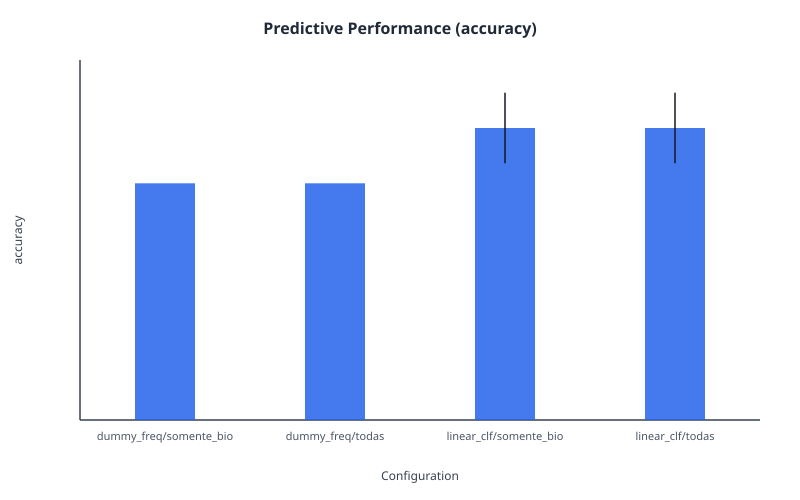

In [8]:
from experimental_ml.reporting import (
    ReportAudience,
    ReportContentSelection,
    ReportFamily,
    build_figure_spec,
    build_table_model,
    load_experiment_artifacts_readonly,
    render_figure,
    render_table_markdown,
    select_report_content,
)

loaded = load_experiment_artifacts_readonly(exp_dir)
sel = select_report_content(loaded, ReportContentSelection(audience=ReportAudience.FULL_LAB))

exibir_markdown("### Desempenho Preditivo\n\n" + render_table_markdown(build_table_model(ReportFamily.D_PREDICTIVE_PERFORMANCE, loaded, sel)))
exibir_markdown("### Comparações Estatísticas\n\n" + render_table_markdown(build_table_model(ReportFamily.E_STATISTICAL_COMPARISONS, loaded, sel)))
exibir_svg(render_figure(build_figure_spec(ReportFamily.D_PREDICTIVE_PERFORMANCE, loaded, sel), fmt="svg"))